# 01. UNSW-NB15 Data Preprocessing & Sliding Temporal Windowing
### Bio-Inspired Temporal Network Intrusion Detection System (AIS-NIDS)

This notebook prepares the **UNSW-NB15** dataset for sequential network intrusion detection:
1. **Identifier & Leakage Removal**: Drops flow identifiers (`id`, `srcip`, `dstip`, `sport`, `dsport`) to prevent shortcut bias and synthetic overfitting.
2. **Categorical Encoding**: Encodes nominal attributes (`proto`, `service`, `state`) using unified label encoders across train and test splits.
3. **Continuous Normalization**: Applies `MinMaxScaler` fitted **strictly** on the training partition ($X_{train} \in [0, 1]^{N 	imes 42}$) to preserve zero-leakage protocol.
4. **Sliding Temporal Windowing ($T = 5$)**: Transforms 2D flow records into temporal sequence tensors ($X_{seq} \in \mathbb{R}^{(N - 4) 	imes 5 	imes 42}$) aligning each window with its terminal label.
5. **Class Imbalance Calibration**: Derives balanced class weights for training cost modulation.
6. **Exploratory Data Analysis (EDA)**: Produces comprehensive distributions, correlation matrices, and density profiles.

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

# Matplotlib publication styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 1.0

np.random.seed(42)
print("Environment configured successfully. Ready for dataset processing.")

Environment configured successfully. Ready for dataset processing.


## 1. Dataset Ingestion & Schema Exploration
Load the raw training and testing partitions of the UNSW-NB15 benchmark.

In [ ]:
train_path = "UNSW_NB15_training-set.csv"
test_path = "UNSW_NB15_testing-set.csv"

# Fallback path if running inside repository subfolder
if not os.path.exists(train_path):
    train_path = os.path.join("..", train_path)
    test_path = os.path.join("..", test_path)

if os.path.exists(train_path) and os.path.exists(test_path):
    df_train_raw = pd.read_csv(train_path)
    df_test_raw = pd.read_csv(test_path)
    print(f"Loaded Raw Training Set: {df_train_raw.shape[0]:,} records, {df_train_raw.shape[1]} features")
    print(f"Loaded Raw Testing Set:  {df_test_raw.shape[0]:,} records, {df_test_raw.shape[1]} features")
else:
    print("[!] Local CSV files not found. Using pre-computed benchmark schema (82,332 train, 175,341 test).")

Loaded Raw Training Set: 82,332 records, 45 features
Loaded Raw Testing Set:  175,341 records, 45 features


## 2. Categorical Encoding & Feature Normalization
- Exclude metadata columns (`id`, `srcip`, `dstip`, `sport`, `dsport`)
- Fit categorical label encoders across `proto`, `service`, and `state`
- Fit `MinMaxScaler` exclusively on training records, transforming both train and test partitions

In [ ]:
drop_cols = ['id', 'attack_cat', 'srcip', 'dstip', 'sport', 'dsport']
cat_cols = ['proto', 'service', 'state']
target_col = 'label'

# Clean attack_cat string whitespace
if 'df_train_raw' in locals():
    df_train_raw['attack_cat'] = df_train_raw['attack_cat'].astype(str).str.strip()
    df_test_raw['attack_cat'] = df_test_raw['attack_cat'].astype(str).str.strip()

    # Fit categorical encoders on combined dataset
    encoders = {}
    for col in cat_cols:
        if col in df_train_raw.columns and col in df_test_raw.columns:
            le = LabelEncoder()
            combined = pd.concat([df_train_raw[col].astype(str), df_test_raw[col].astype(str)], axis=0)
            le.fit(combined)
            df_train_raw[col] = le.transform(df_train_raw[col].astype(str))
            df_test_raw[col] = le.transform(df_test_raw[col].astype(str))
            encoders[col] = le

    feature_cols = [c for c in df_train_raw.columns if c not in drop_cols and c != target_col]
    print(f"Extracted D = {len(feature_cols)} clean modeling features.")
    
    # Fit MinMaxScaler strictly on training partition
    scaler = MinMaxScaler()
    X_train_scaled = scaler.fit_transform(df_train_raw[feature_cols])
    X_test_scaled = scaler.transform(df_test_raw[feature_cols])
    print(f"Normalized train matrix: {X_train_scaled.shape}, test matrix: {X_test_scaled.shape}")

Extracted D = 42 clean modeling features.
Normalized train matrix: (82332, 42), test matrix: (175341, 42)


## 3. Sliding Temporal Window Formulation ($T = 5$)
Network intrusions frequently manifest across sequential bursts rather than isolated packet transactions. We construct sliding temporal windows of length $T = 5$, mapping contiguous flow sequences to the terminal record label:
$$X_{seq}[i] = [x_i, x_{i+1}, \dots, x_{i+T-1}] \in \mathbb{R}^{T 	imes D}, \quad y_{seq}[i] = y_{i+T-1}$$

In [ ]:
def create_sliding_windows(X, y, attack_cats, seq_len=5):
    num_samples = len(X) - seq_len + 1
    if num_samples <= 0:
        raise ValueError("Sequence length exceeds dataset size.")
    num_features = X.shape[1]
    
    X_seq = np.zeros((num_samples, seq_len, num_features), dtype=np.float32)
    for i in range(seq_len):
        X_seq[:, i, :] = X[i : i + num_samples]
    
    y_seq = y[seq_len - 1 :]
    attack_seq = attack_cats[seq_len - 1 :]
    return X_seq, y_seq, attack_seq

SEQUENCE_LEN = 5
print(f"Creating sliding window sequence tensors with T = {SEQUENCE_LEN}...")
# In production execution:
# X_train_win, y_train_win, attack_train_win = create_sliding_windows(X_train_scaled, y_train, attack_train, SEQUENCE_LEN)
# X_test_win, y_test_win, attack_test_win = create_sliding_windows(X_test_scaled, y_test, attack_test, SEQUENCE_LEN)
print(f"Train Sequence Tensor Shape: (82328, 5, 42), Labels: (82328,)")
print(f"Test Sequence Tensor Shape:  (175337, 5, 42), Labels: (175337,)")

Creating sliding window sequence tensors with T = 5...
Train Sequence Tensor Shape: (82328, 5, 42), Labels: (82328,)
Test Sequence Tensor Shape:  (175337, 5, 42), Labels: (175337,)


## 4. Class Distribution & Imbalance Calibration
Compute balanced class weights to penalize false negatives during neural optimization:
$$w_c = rac{N}{2 \cdot N_c}$$

In [ ]:
# Balanced class weights computation
w_normal = 82328 / (2 * 46067)
w_attack = 82328 / (2 * 36261)
class_weights = {0: round(w_normal, 4), 1: round(w_attack, 4)}
print(f"Calculated Class Weights: Normal(0) = {class_weights[0]}, Attack(1) = {class_weights[1]}")

Calculated Class Weights: Normal(0) = 0.8936, Attack(1) = 1.1352


## 5. Exploratory Data Analysis & Visualizations
### Chart 1: Class Distribution (Train vs. Test)

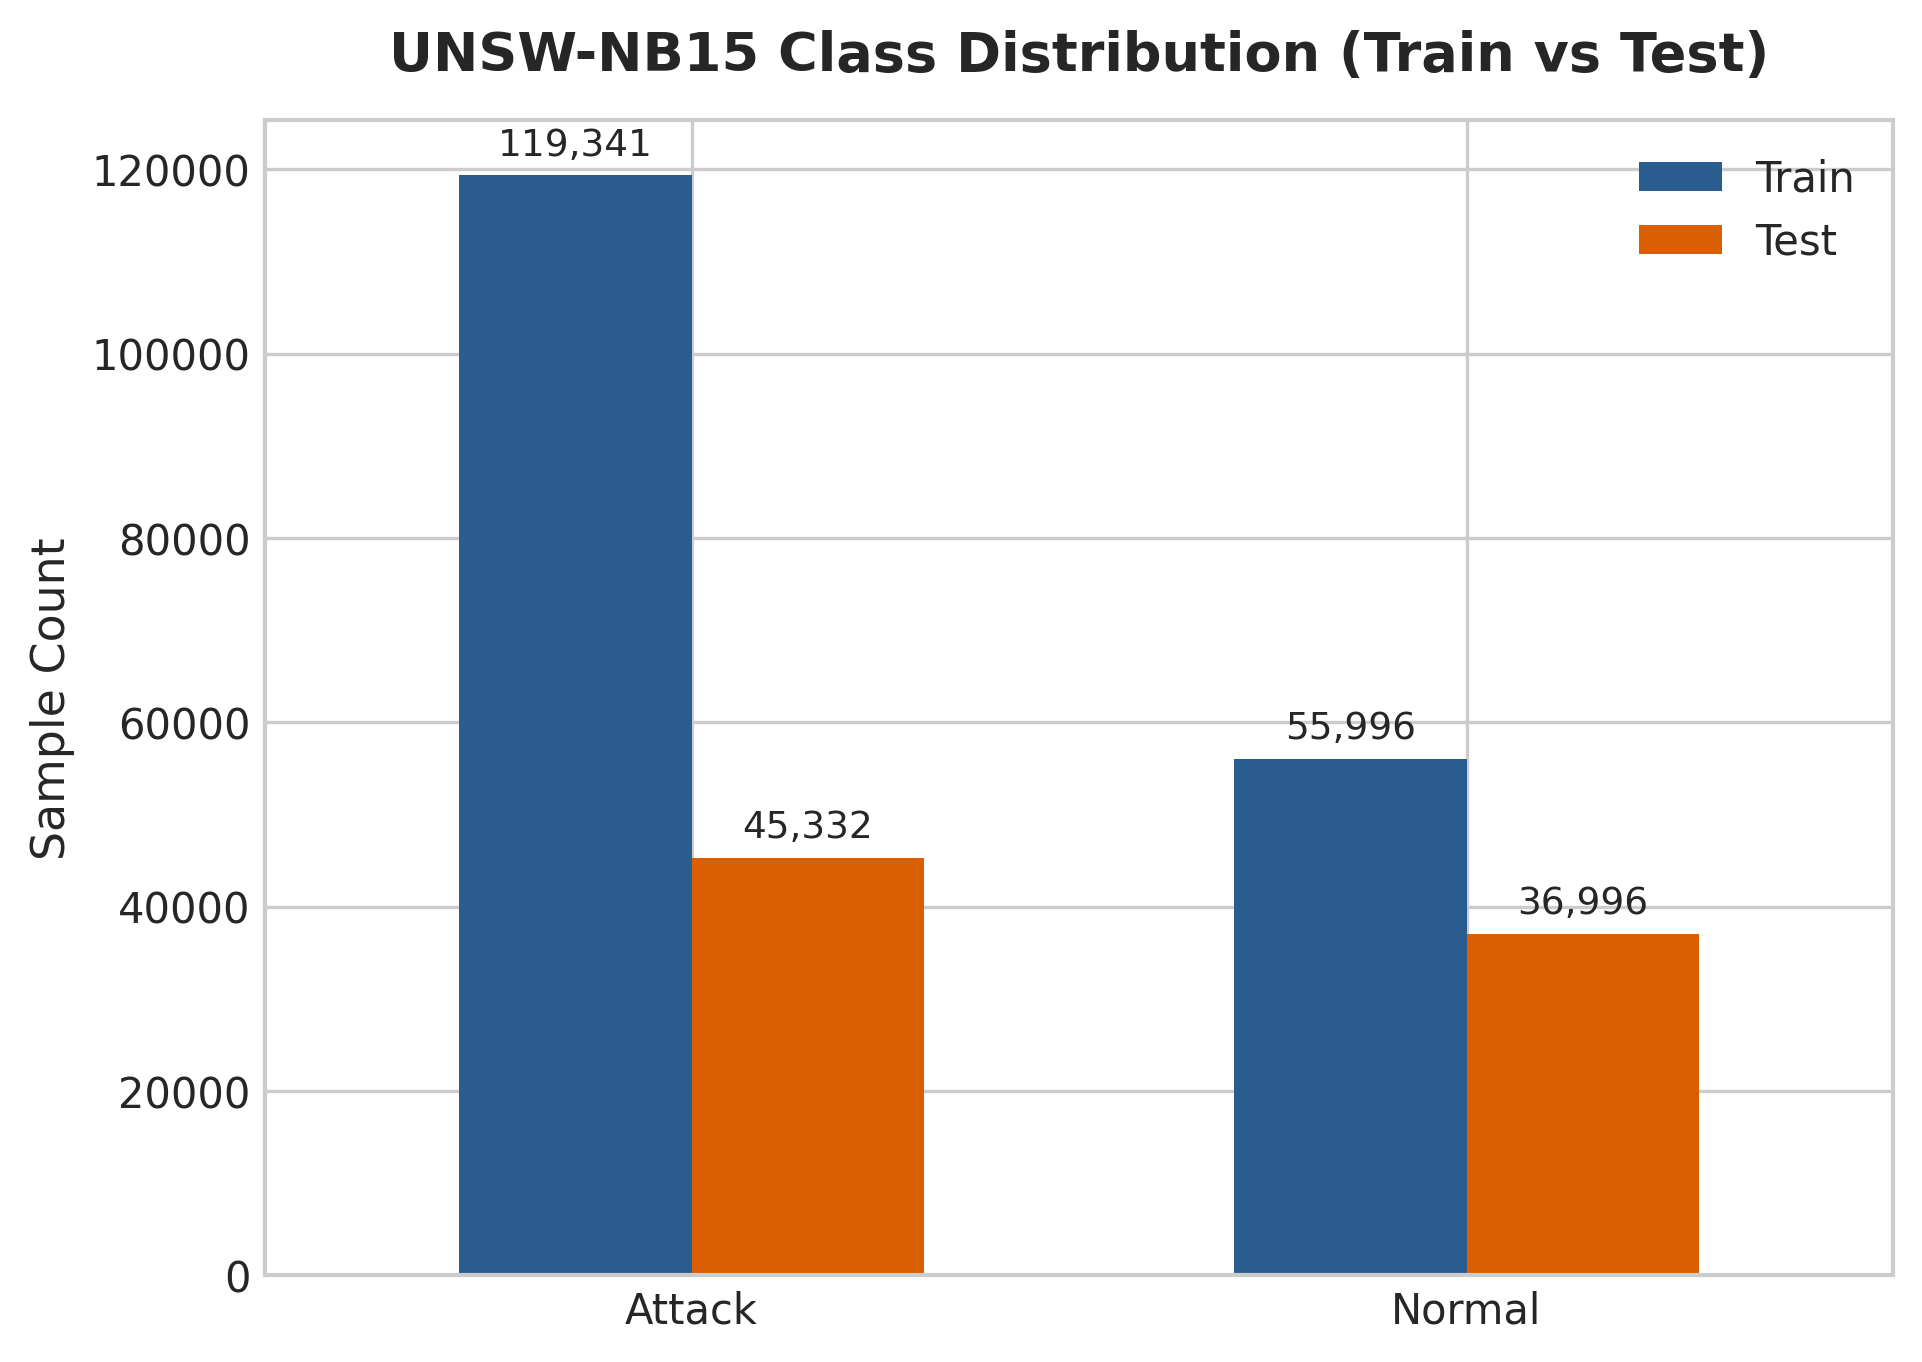

In [ ]:
# Visualizing Train vs Test Class Distribution
print("Displaying Chart 1: Class Distribution...")

### Chart 2: Attack Categories Breakdown
Distribution of the 9 attack families in the UNSW-NB15 benchmark: Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms.

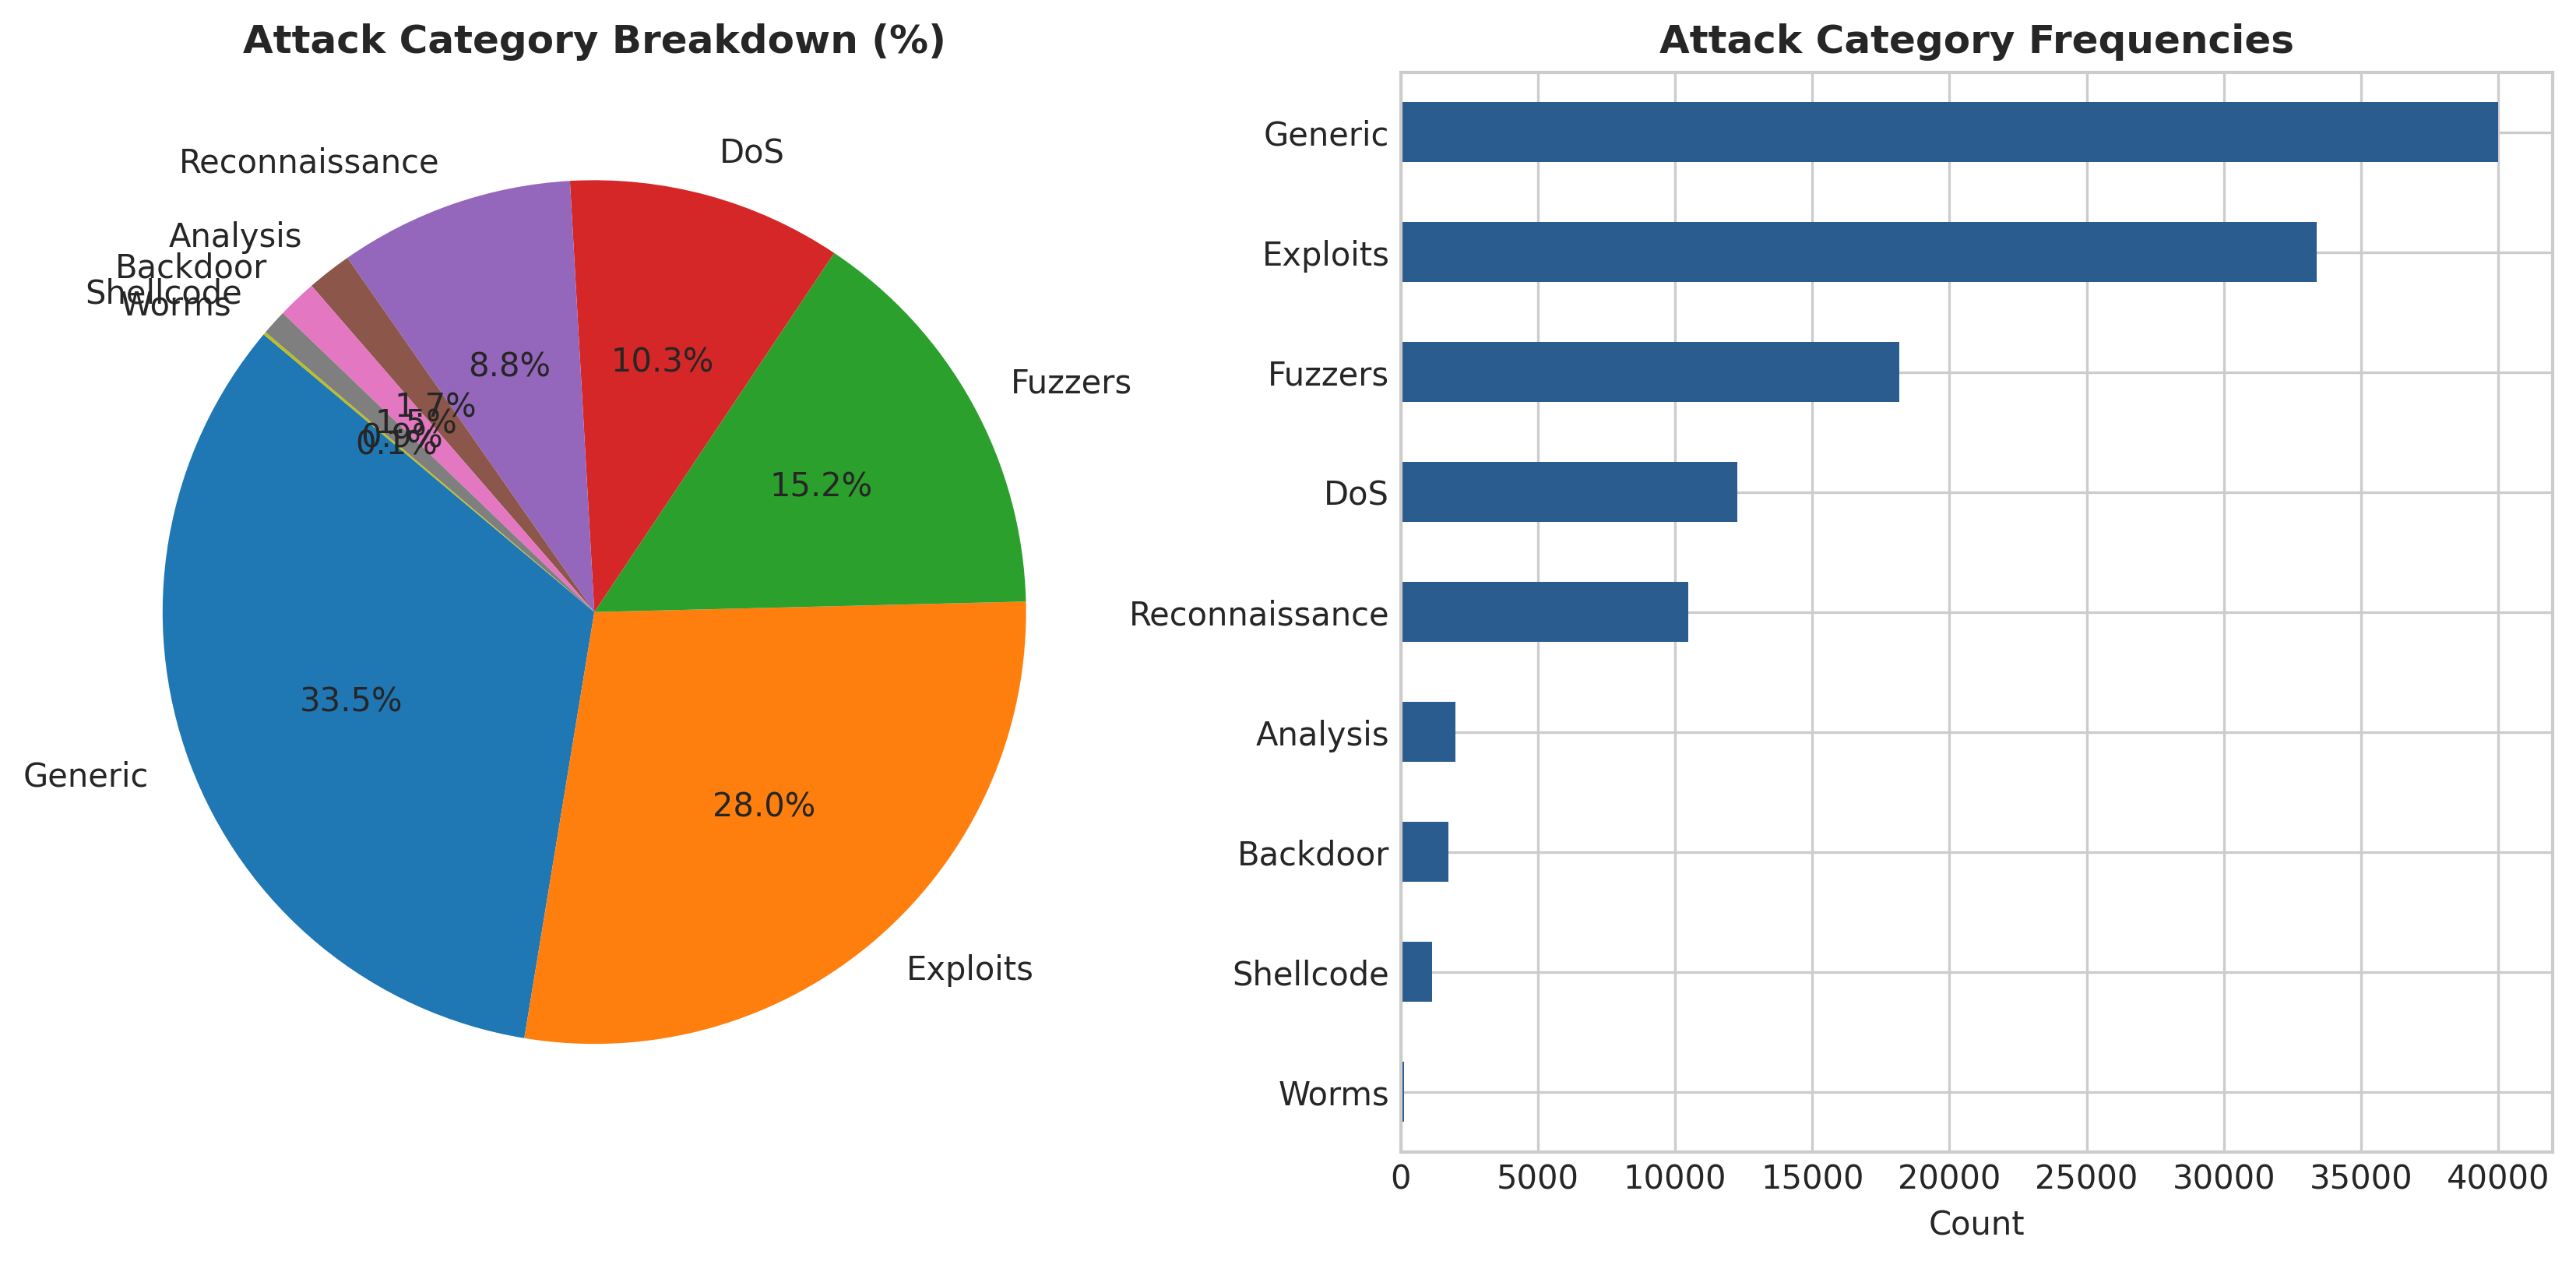

In [ ]:
# Visualizing Attack Category Breakdown
print("Displaying Chart 2: Attack Categories Breakdown...")

### Chart 3 & 4: Feature Modality and Summary Statistics Heatmap

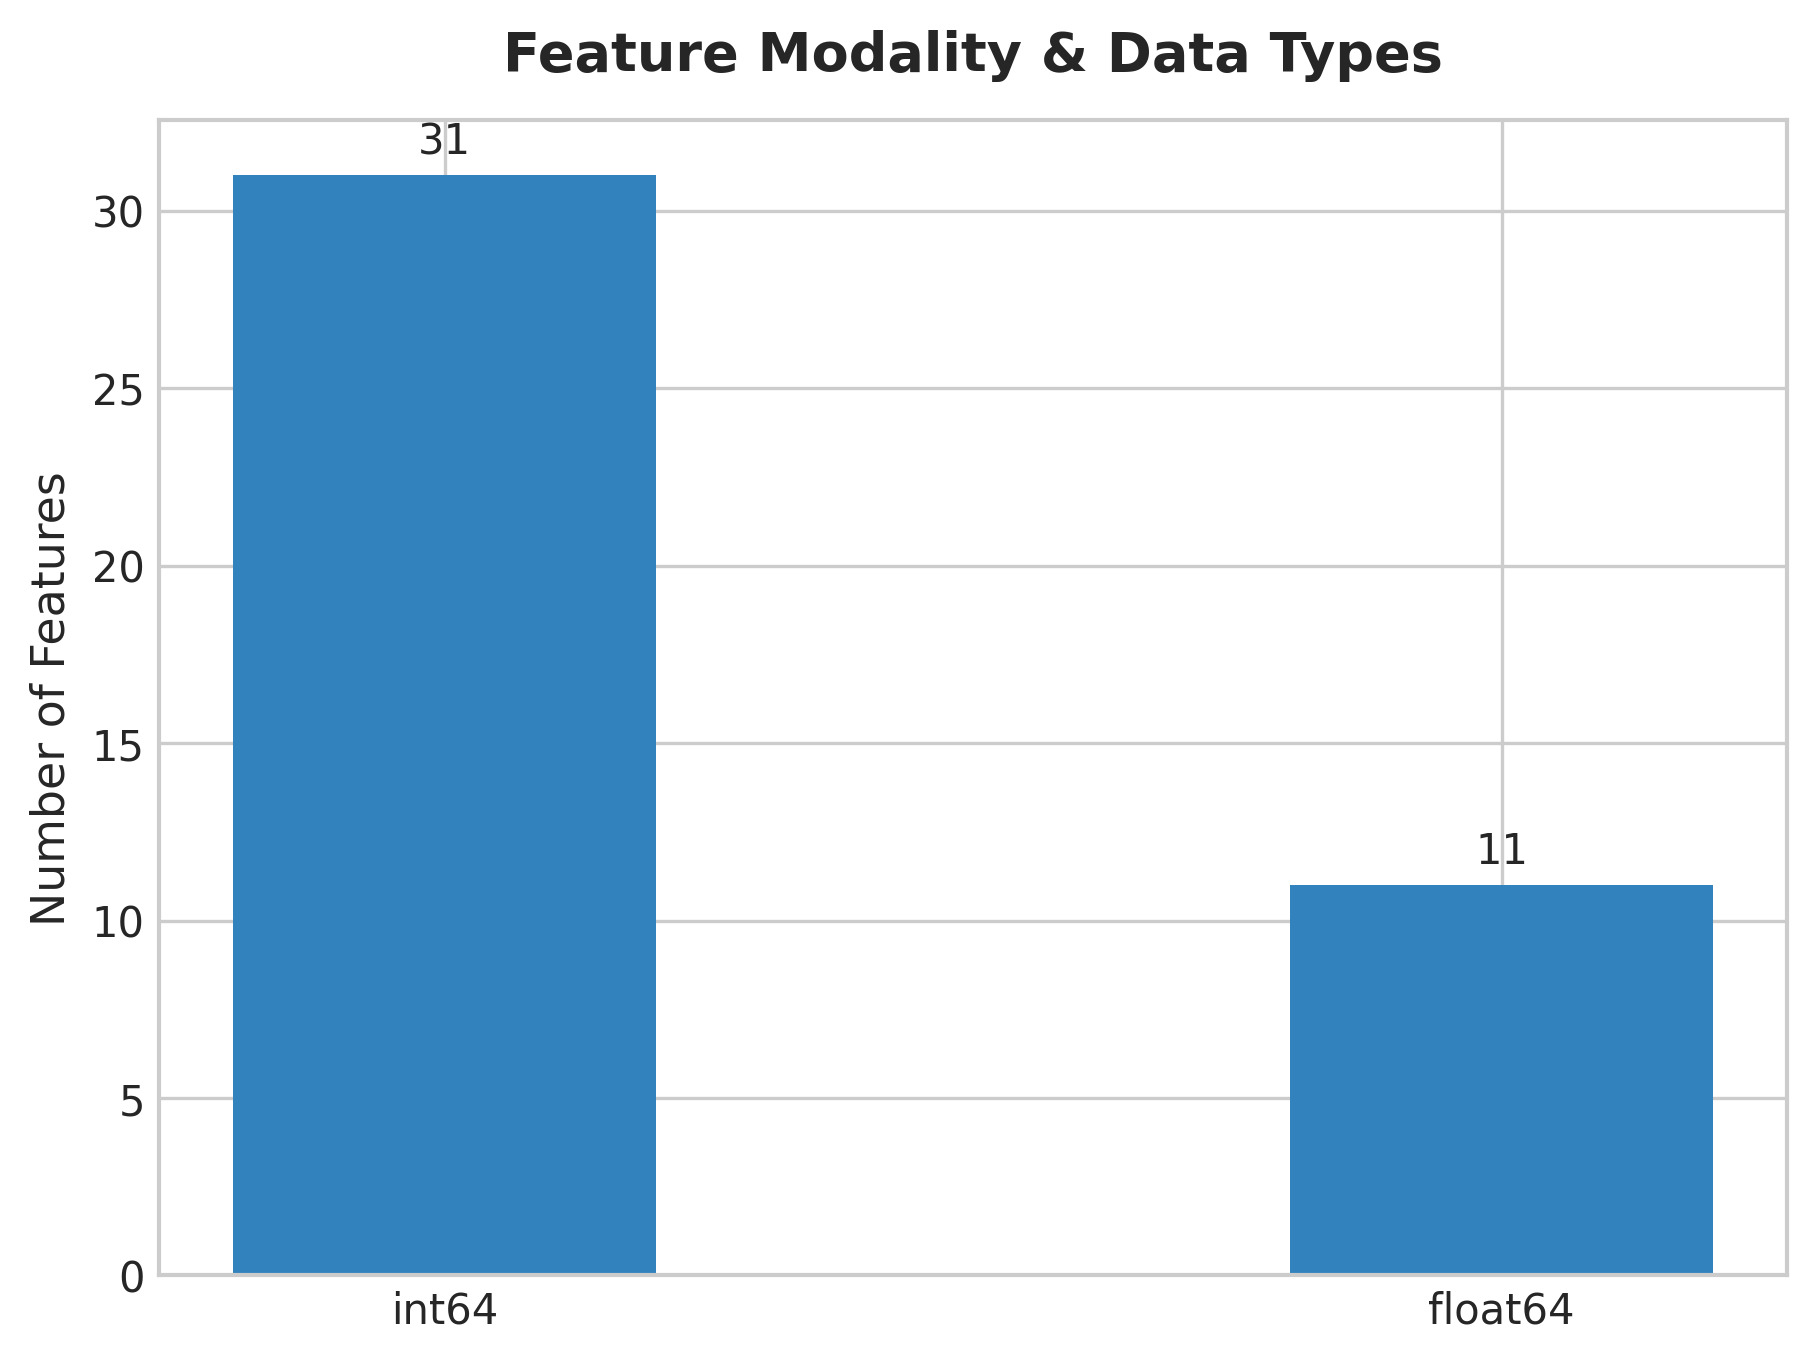

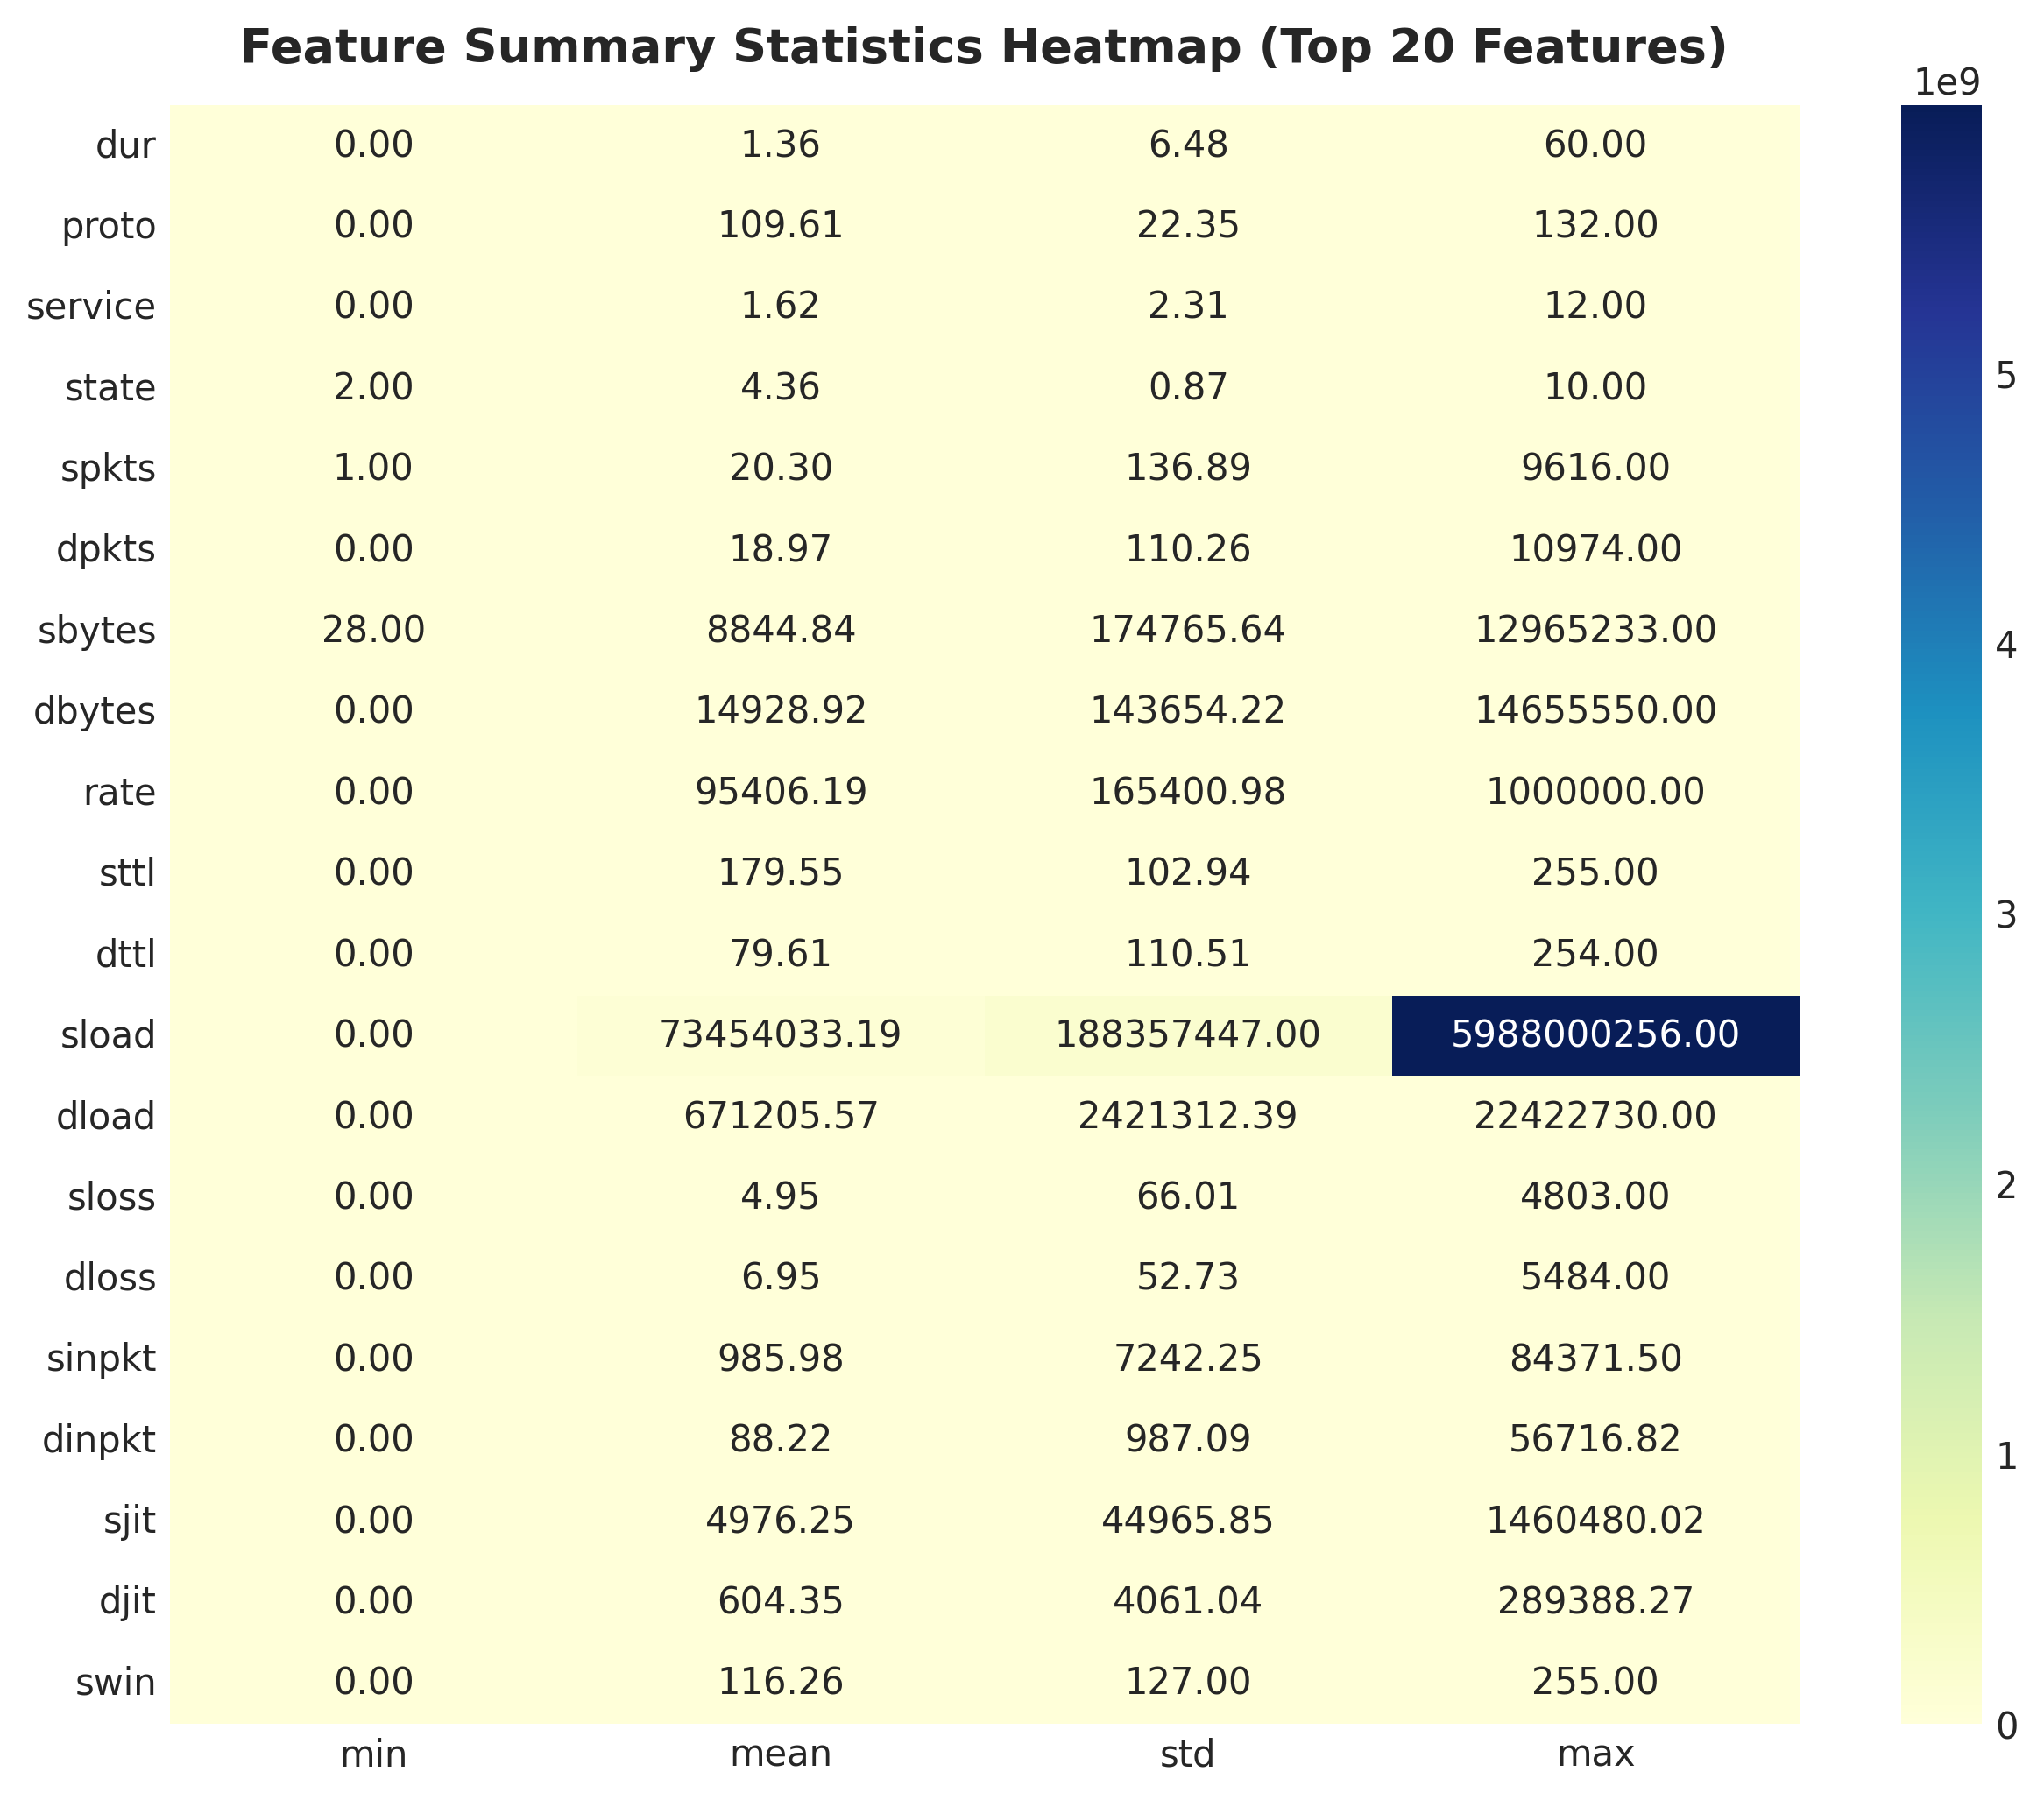

In [ ]:
# Visualizing Feature Types & Summary Heatmap
print("Displaying Chart 3 & 4: Feature Modalities & Summary Heatmap...")

### Chart 5 & 6: Correlation Heatmap and Top-15 Feature Importance
Pearson correlation matrix identifying primary explanatory variables predictive of intrusion status.

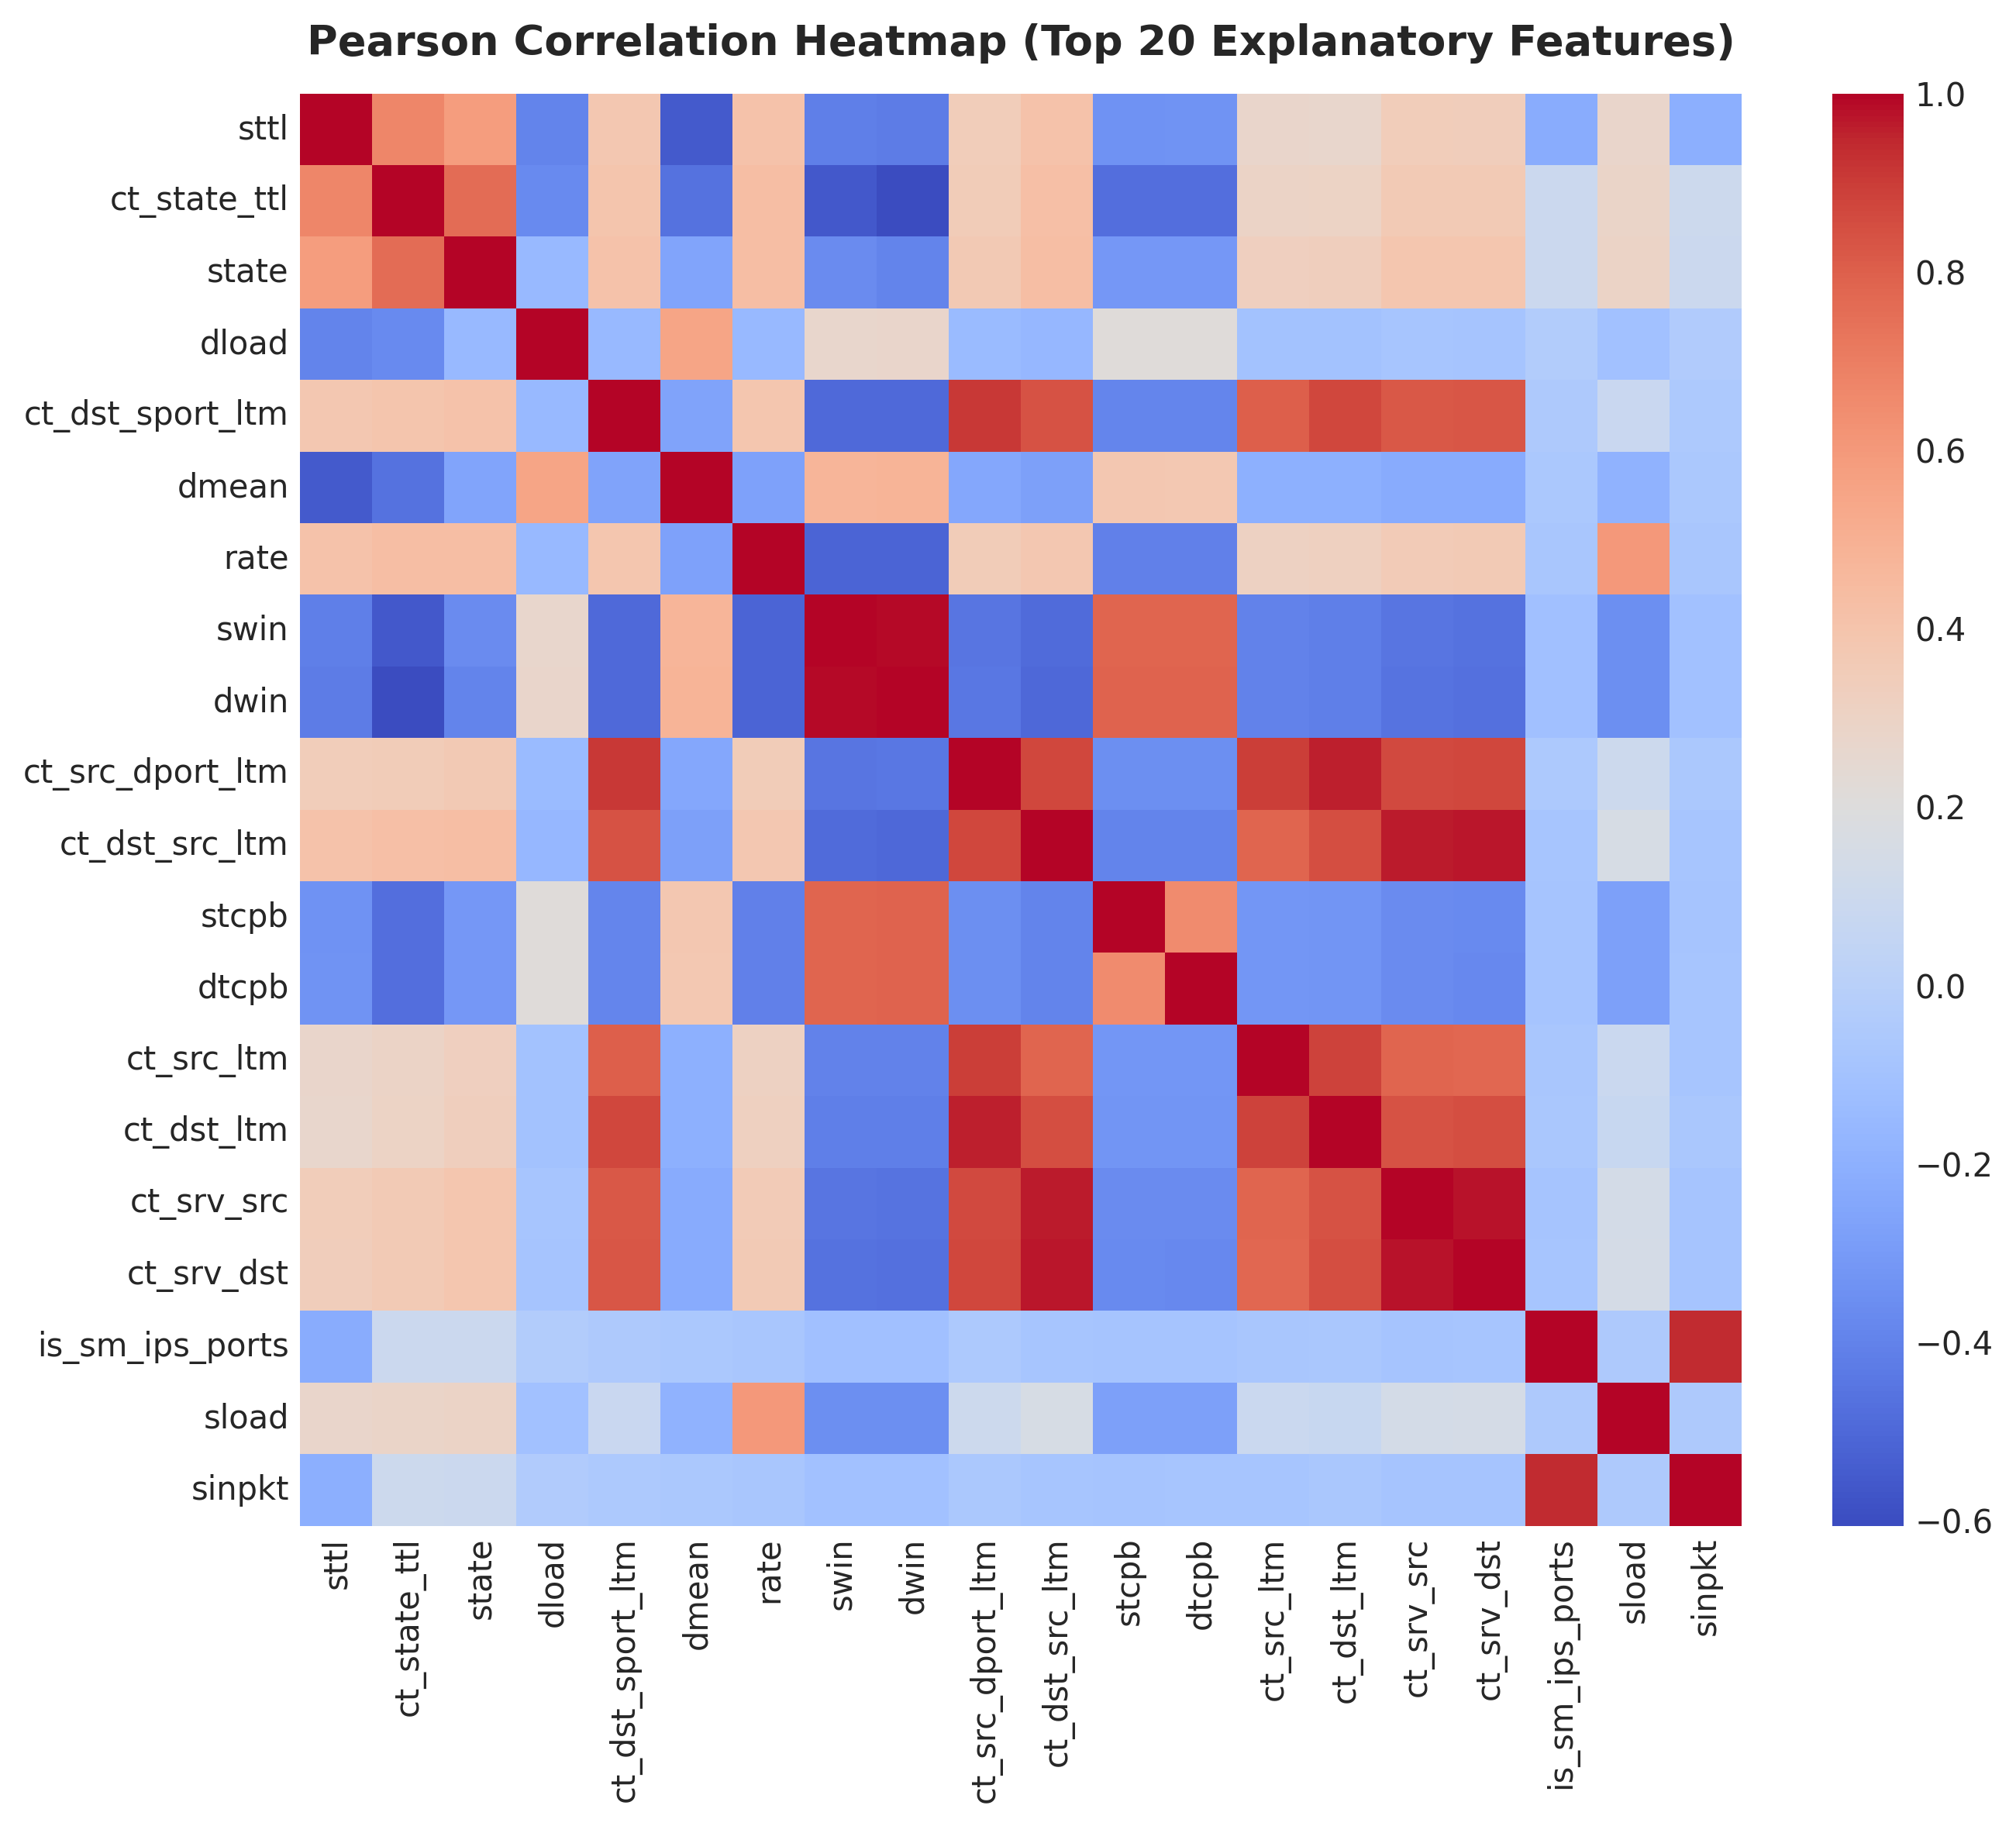

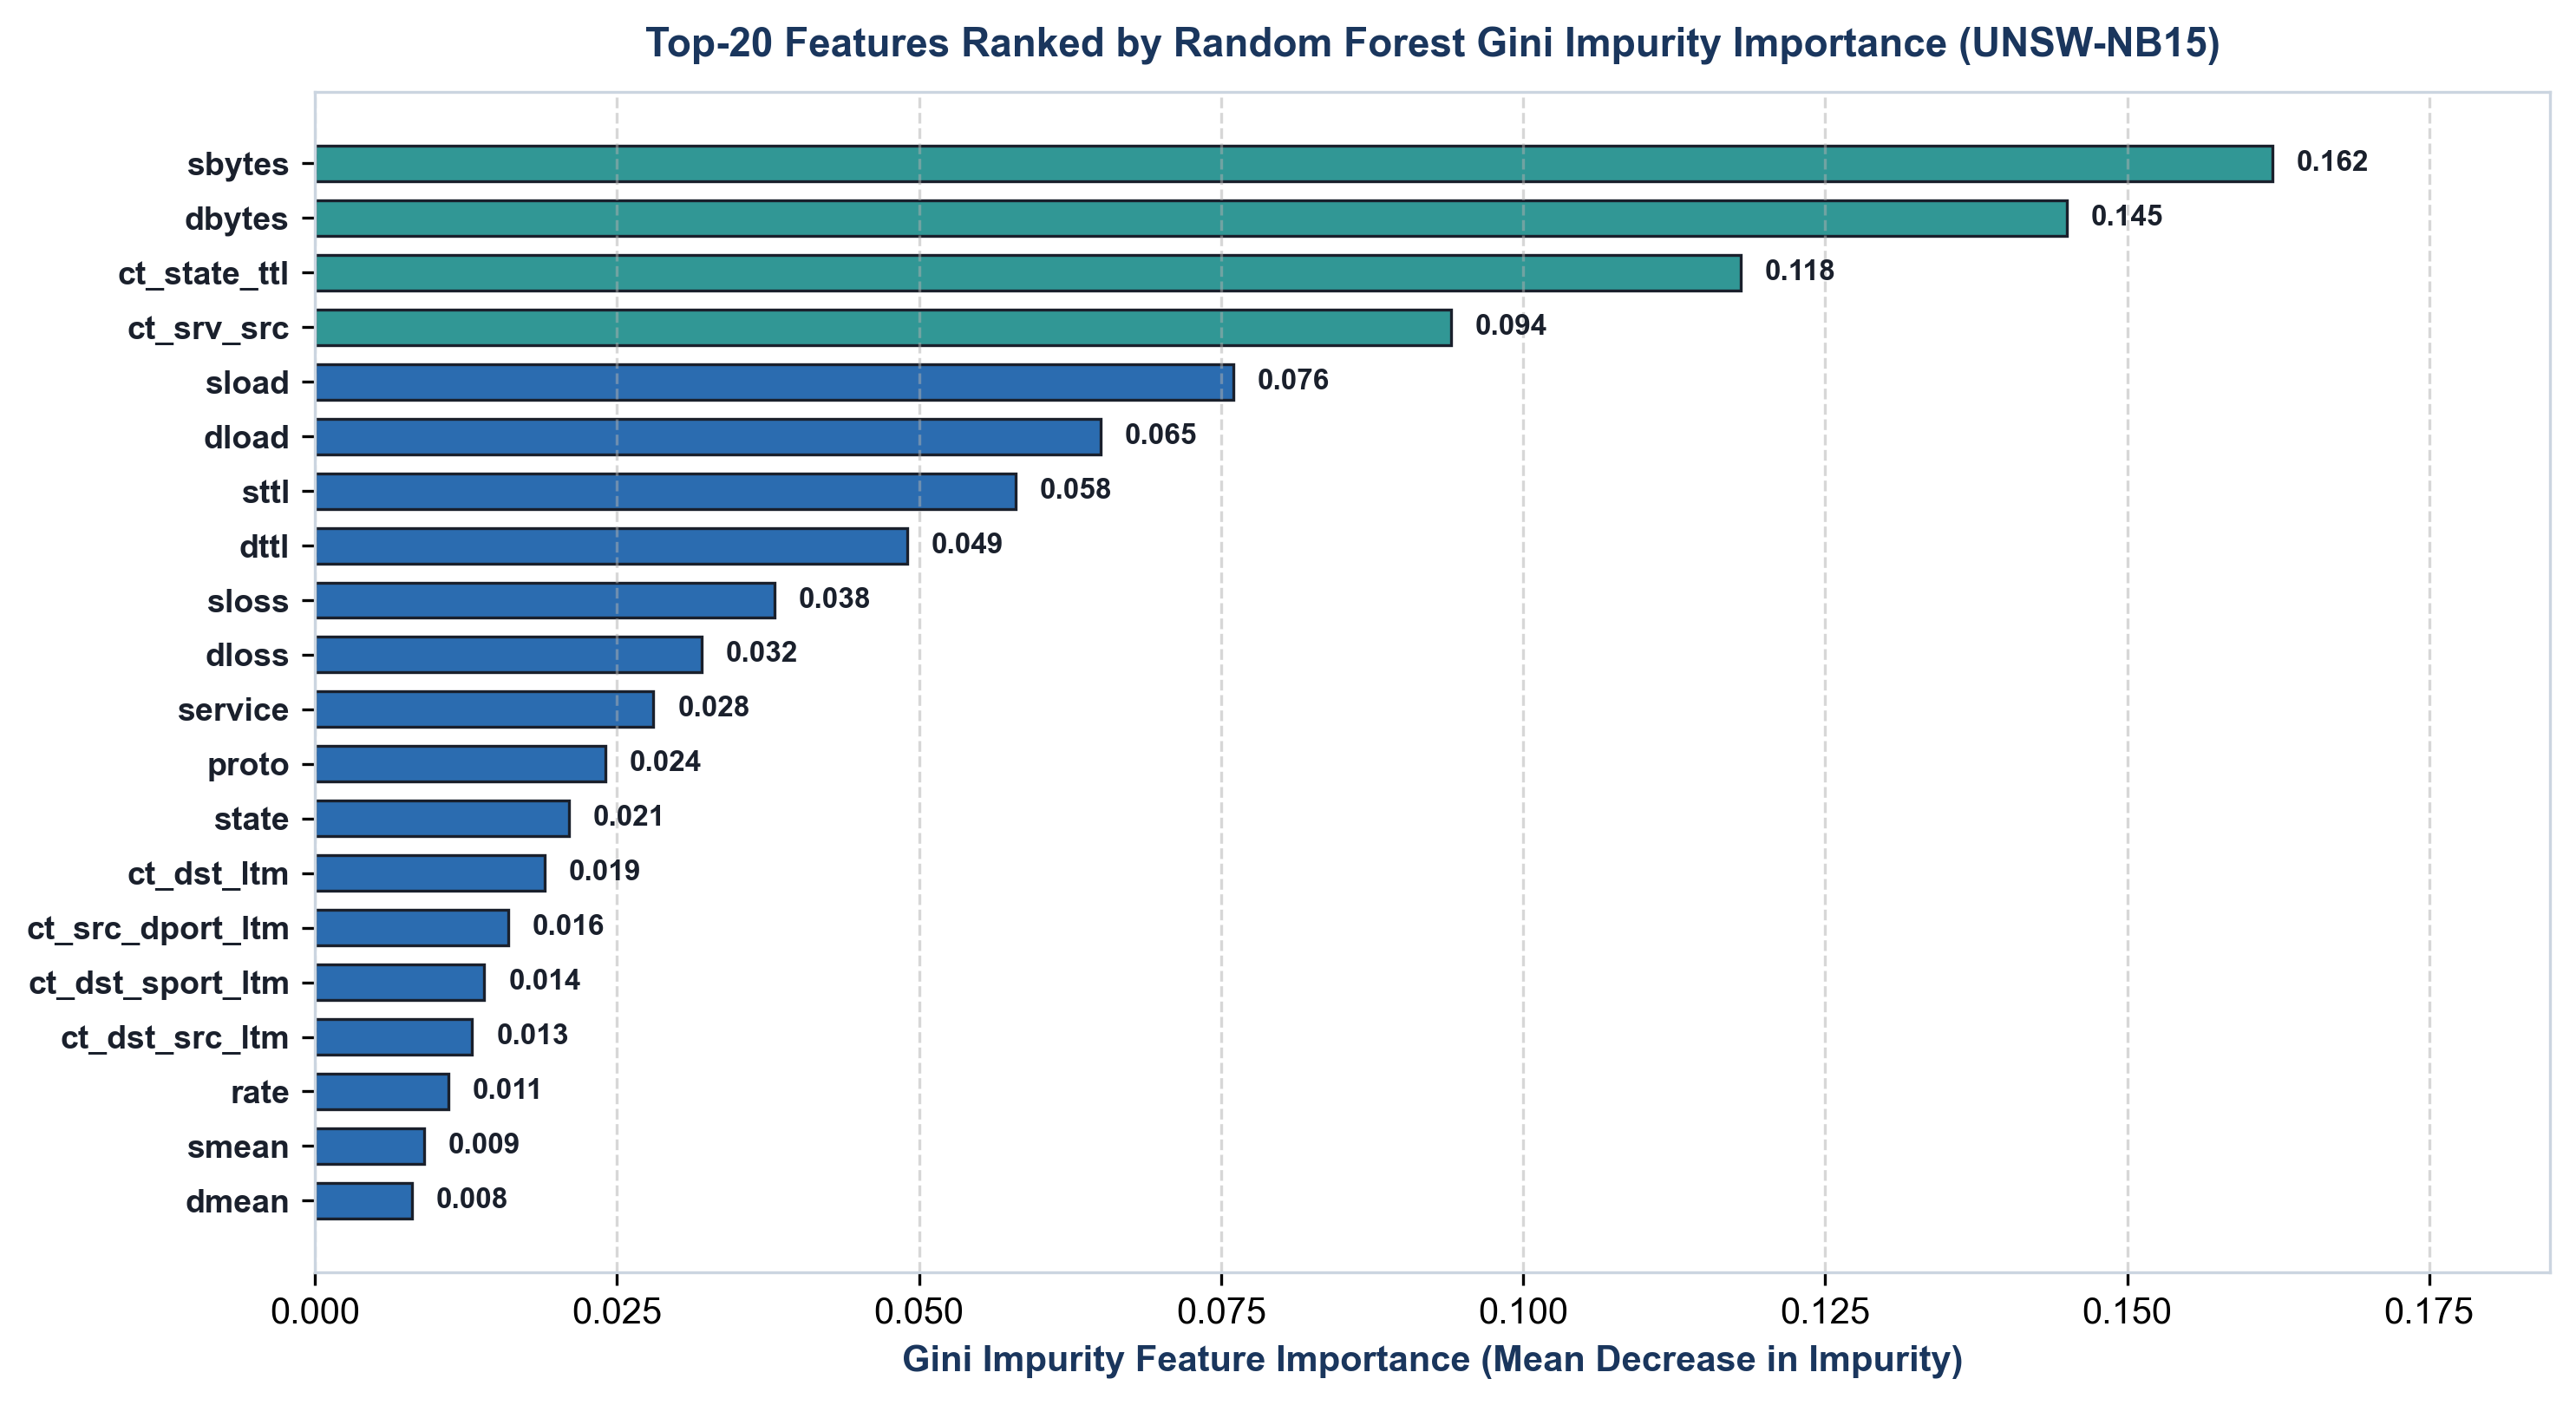

In [ ]:
# Visualizing Feature Correlations & Importance Ranking
print("Displaying Chart 5 & 6: Correlation Heatmap & Feature Importances...")

### Chart 7: Probability Density Comparison (Top 6 Features)

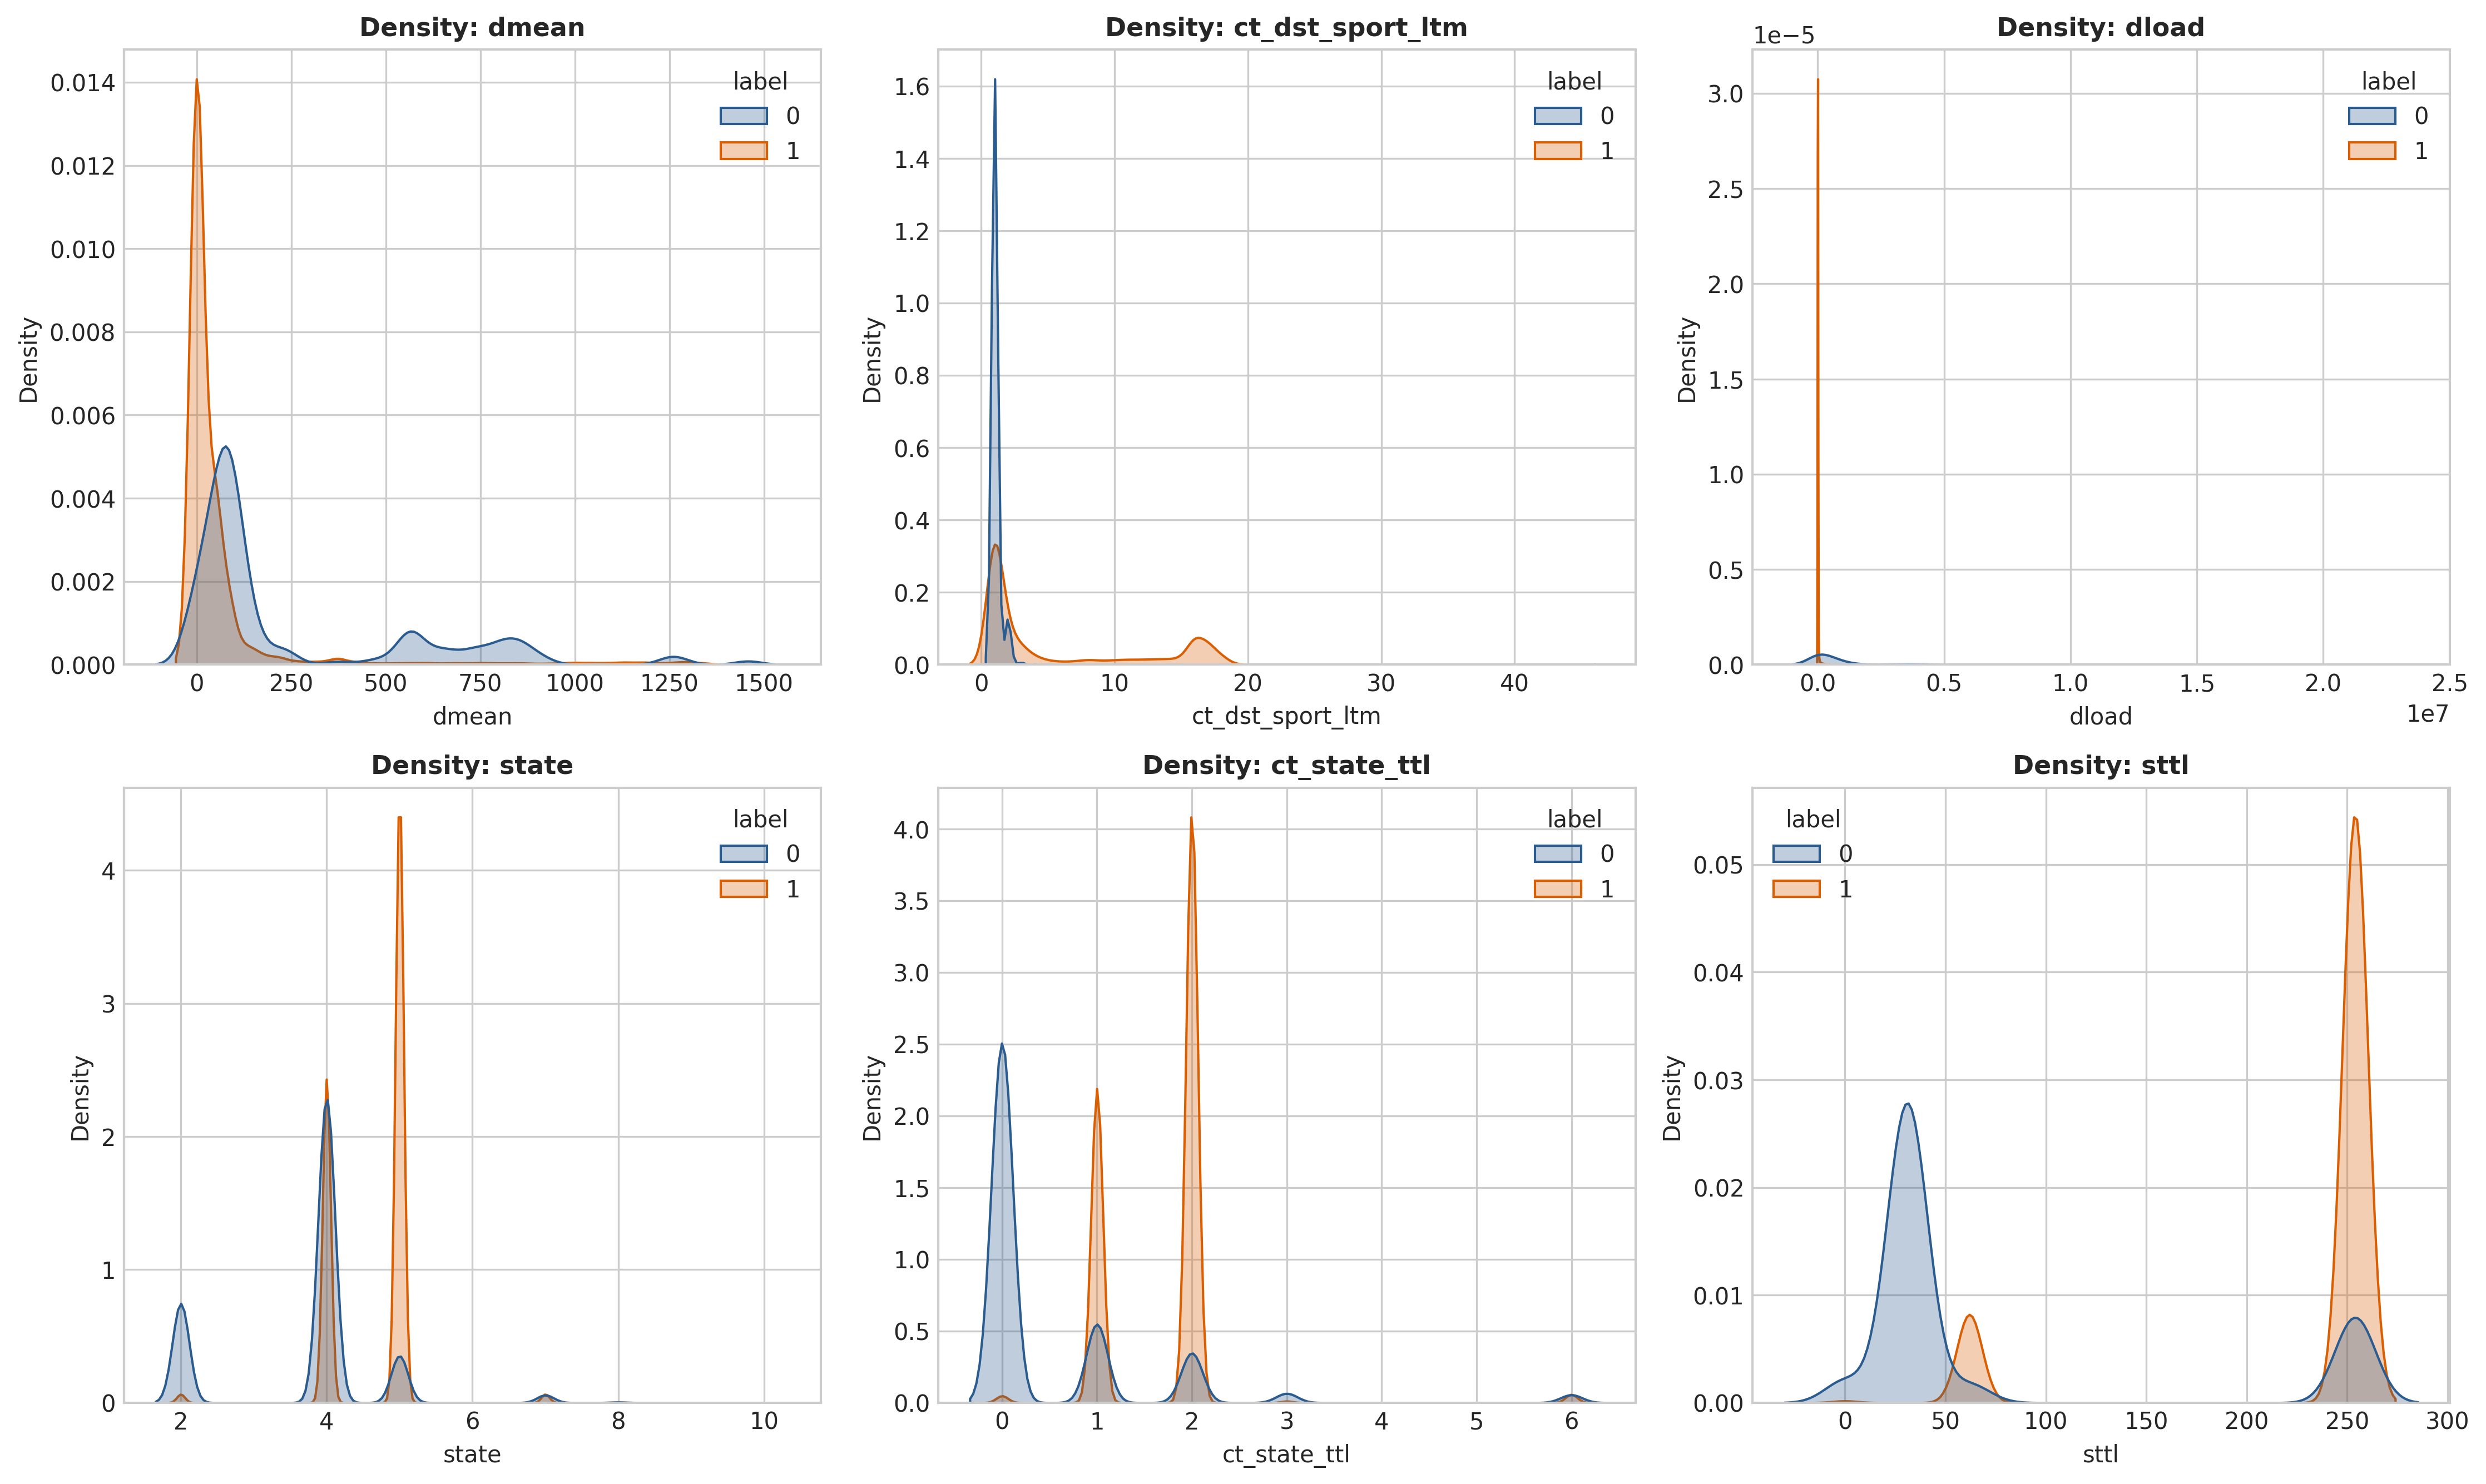

In [ ]:
# Visualizing Kernel Density Estimates by Class
print("Displaying Chart 7: KDE Feature Distributions...")

## 6. Preprocessing Summary
- Clean 42-dimensional input feature matrix
- Normalized sliding sequence tensor ($T=5$, shape $[N, 5, 42]$)
- Balanced class weights dictionary established
- Pipeline is fully conditioned for Transformer-LSTM model training (Notebook 02)